# Regresión: ElasticNet

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "elasticnet"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,ElasticNet
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

Se comparan tres variantes del target: nativo, sqrt y log1p (estas dos con corrección de smearing). Su justificación y el sesgo de retransformación se explican en [Variantes del target](#mod-variantes) y [Sesgo de retransformación](#mod-smearing).

### Espacio de Búsqueda

Se exploraron 10 combinaciones de la fuerza de la penalización (`alpha`, log-uniforme entre 1e-4 y 1e1) y de la mezcla entre L1 y L2 (`l1_ratio`, uniforme entre 0.1 y 0.9: cerca de 0.1 se parece a Ridge y cerca de 0.9 a Lasso).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
alpha,log-uniforme entre 0.0001 y 10
l1_ratio,uniforme entre 0.1 y 0.9


### Validación Cruzada por Variante

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.8997 ± 0.4870  R² = 0.2011  (5 s)
✓ sqrt + smearing    RMSE = 6.9331 ± 0.4776  R² = 0.1931  (1 s)
✓ log1p + smearing   RMSE = 7.0656 ± 0.4796  R² = 0.1618  (1 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.900 ± 0.487,4.907 ± 0.188,0.201 ± 0.016,5.0
sqrt + smearing,6.933 ± 0.478,4.917 ± 0.191,0.193 ± 0.018,1.0
log1p + smearing,7.066 ± 0.480,5.002 ± 0.191,0.162 ± 0.021,1.0


El nativo obtiene el menor RMSE (6.900 ± 0.487) y el mayor R² (0.201 ± 0.016), igual que los demás modelos lineales. sqrt queda a 0.03 puntos (6.933, R² = 0.193) y log1p es la peor (7.066, R² = 0.162), aunque es la mejor versión de log1p entre los modelos lineales.

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,alpha,l1_ratio
Variante,,
Nativo,0.014450,0.3330
sqrt + smearing,0.007459,0.8606
log1p + smearing,0.101300,0.6665


El nativo elige una penalización pequeña (`alpha` = 0.0145) con una mezcla más cercana a Ridge (`l1_ratio` = 0.33). sqrt elige una todavía menor y más cercana a Lasso (`alpha` = 0.0075, `l1_ratio` = 0.86). En ambos casos la penalización es tan pequeña que el modelo es casi OLS. log1p vuelve a elegir una penalización mayor (0.101).

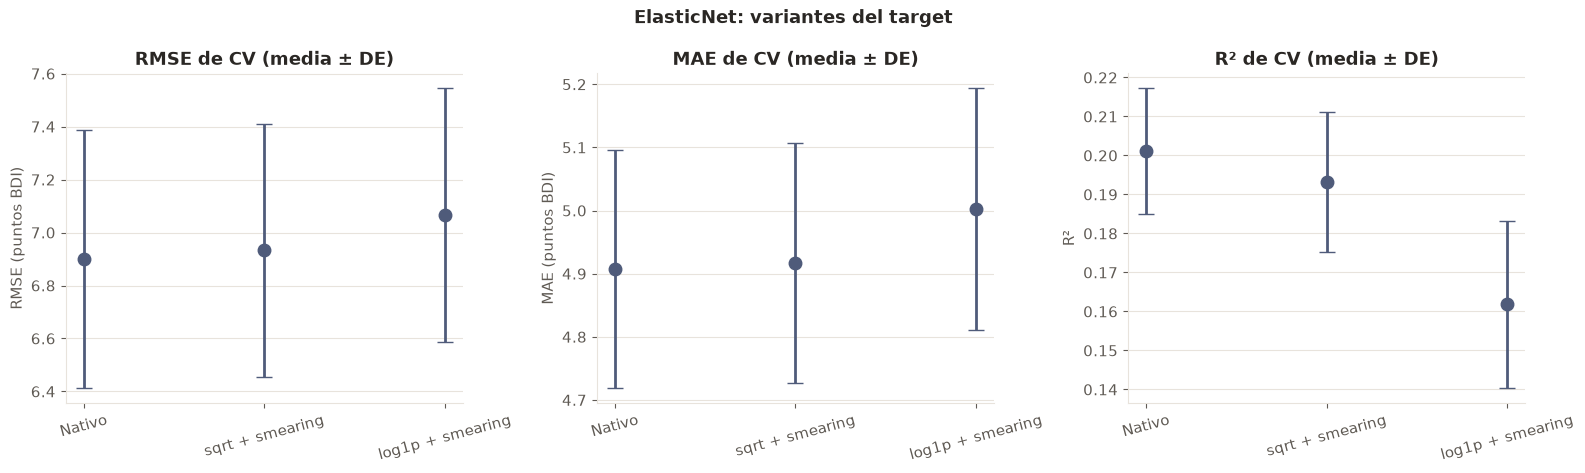

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica repite el patrón de los demás modelos lineales: el nativo y sqrt son equivalentes y log1p es peor en las tres métricas.

### Sesgo de Retransformación: Efecto del Smearing

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.788,-1.514,7.113,4.670,0.157
Con smearing,7.269,-0.032,6.950,4.917,0.195


Sin smearing, la media predicha con sqrt es 5.79, 1.51 puntos por debajo de la real. Con la corrección queda en 7.27, el RMSE baja de 7.113 a 6.950 y el R² sube de 0.157 a 0.195, a costa de un MAE mayor (de 4.670 a 4.917).

### Selección del Mejor Modelo ElasticNet

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,ElasticNet
Variante ganadora,Nativo
RMSE de CV,6.8997 ± 0.4870
MAE de CV,4.9070 ± 0.1881
R² de CV,0.2011 ± 0.0161
Hiperparámetros,"alpha=0.01445, l1_ratio=0.333"
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (6.8997 ± 0.4870) y ninguna opción más simple queda a menos de una desviación estándar (0.4870).


Gana la variante nativa por menor RMSE medio (6.8997). Con una penalización tan pequeña, ElasticNet es prácticamente la regresión lineal sin penalizar.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/elasticnet: resultados_cv.csv, ganador.json y elasticnet_nativo.joblib
